# 💎 Diamond Price Prediction: Scaling & Normalization Benchmark

Welcome to this Kaggle notebook! In this data science project, our primary goal is to **predict diamond prices** based on their physical attributes and quality features (the 4 Cs), while rigorously testing and benchmarking **12 different data scaling and normalization techniques** to evaluate their impact on regression model performance.

---

## 📌 Project Overview

Feature scaling and matrix balancing are crucial steps in machine learning and optimization pipelines. Different scaling strategies alter the distribution and scale of numerical features in unique ways, directly affecting gradient descent convergence, distance metrics, and overall model accuracy.

In this notebook, we experiment with **12 specific scaling and normalization techniques** (as outlined in our experimental design) to determine which preprocessing pipeline yields the lowest error and highest predictive power ($R^2$, $MAE$, $RMSE$) for diamond valuation.

---

## 📊 Dataset Features (The 4 Cs & Dimensions)

The [dataset](https://www.kaggle.com/datasets/nancyalaswad90/diamonds-prices/data) contains the classic **4 Cs of Diamonds** alongside precise physical dimensions:

* **Quality Features:** `carat`, `cut`, `color`, `clarity`.
* **Physical Dimensions:** `depth`, `table`, `x`, `y`, `z`.
* **Target Variable:** `price` (in US dollars $\$$).

---

## 🛠️ The 12 Scaling & Normalization Techniques Evaluated

Here are the 12 techniques implemented and benchmarked in our experimental pipeline:

1. **Normalisation [0, 1]**: Scales features to a bounded range between 0 and 1.
2. **Normalisation [-1, 1]**: Scales features symmetrically to a range between -1 and 1.
3. **Equibration**: Balances matrix rows/columns to improve numerical stability.
4. **Arithmetic mean**: Centers or scales data based on the arithmetic mean.
5. **Geometric mean**: Utilizes geometric mean scaling for skewed or multiplicative relationships.
6. **de Buchet ($p = 1$)**: Applies de Buchet normalization scaling with norm $p=1$.
7. **de Buchet ($p = 2$)**: Applies de Buchet normalization scaling with Euclidean norm $p=2$.
8. **de Buchet ($p = \infty$)**: Applies de Buchet normalization scaling with maximum norm ($p=\infty$).
9. **IBM MPSX**: Scaling method derived from mathematical programming and matrix scaling traditions (MPSX format standards).
10. **Lp-norm ($p = 1$)**: Normalizes feature vectors using Manhattan norm ($L1$).
11. **Lp-norm ($p = 2$)**: Normalizes feature vectors using Euclidean norm ($L2$).
12. **Lp-norm ($p = \infty$)**: Normalizes feature vectors using Chebyshev norm ($L\infty$).

---

## 🎯 Workflow & Methodology

```
┌─────────────────┐     ┌─────────────────────┐     ┌──────────────────────┐
│  Data Cleaning  │ ──► │ Feature Engineering │ ──► │  Categorical Encod.  │
└─────────────────┘     └─────────────────────┘     └──────────────────────┘
                                                               │
                                                               ▼
┌─────────────────┐     ┌─────────────────────┐     ┌──────────────────────┐
│  Final Ranking  │ ◄── │   Model Evaluation  │ ◄── │   Apply 12 Scalers   │
│  & Conclusion   │     │   (R², MAE, RMSE)   │     │  Experiment Pipeline │
└─────────────────┘     └─────────────────────┘     └──────────────────────┘

```

1. **Exploratory Data Analysis (EDA):** Inspecting feature distributions and outlier bounds.
2. **Preprocessing & Encoding:** Preparing numerical matrices and encoding categorical features (`cut`, `color`, `clarity`).
3. **Experiment Execution:** Looping through all 12 scaling and normalization methods across our regression models.
4. **Benchmarking & Comparison:** Evaluating metrics to find the optimal scaling approach.

---

## 🚀 Let's Get Started!

Scroll down to dive into the code, implementation details, and performance visualizations. If you find this notebook useful, please consider giving it an **Upvote**! 💡✨

# **1. Import The Libraries I'll Need For The Statistics**

In [ ]:
import numpy as np
import pandas as pd

# **2. Import The Library I'll Need For The Visualization**

In [ ]:
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

# **3. Read The Data and Display a Sample of It's Content**

In [ ]:
df = pd.read_csv('/content/diamonds.csv')
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


# **4. Exploratory Data Analysis (EDA) 👀**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,53940.0,26969.500000,15571.281097,0.0,13484.75,26969.50,40454.25,53939.00
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(53940, 11)

___________________________________________________________


# **5. Data Cleaning 🧹 & Data Preprocessing ⚙️**

### **Remove the `Unnamed: 0` column**

In [ ]:
df.drop(columns='Unnamed: 0', inplace=True)
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


### **Check if the  `x`, `y`, and `z` columns have 0 values**

In [ ]:
df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)].shape

(20, 10)

### **Remove the 0 values from the `x`, `y`, and `z` columns**

In [ ]:
df = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)]
df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)].shape

(0, 10)

### **Create a `size` column by multiplying the three dimensions (x × y × z)**

In [ ]:
df['size'] = df['x'] * df['y'] * df['z']
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,size
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,38.202030
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,34.505856
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,38.076885
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,46.724580
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,51.917250


### **Ordinal Encoding**

#### Get the unique values in the `cut`, `color`, and `clarity` columns to assign numerical values based on the importance of each category

In [ ]:
print(f'Values of cut: {set(df['cut'])}')
print(f'Values of color: {set(df['color'])}')
print(f'Values of clarity: {set(df['clarity'])}')

Values of cut: {'Good', 'Fair', 'Premium', 'Very Good', 'Ideal'}
Values of color: {'I', 'J', 'F', 'E', 'G', 'D', 'H'}
Values of clarity: {'VVS2', 'I1', 'VS1', 'VVS1', 'SI2', 'IF', 'VS2', 'SI1'}


In [ ]:
cut_map = {'Fair': 1, 'Good': 2, 'Very Good': 3, 'Premium': 4, 'Ideal': 5}
color_map = {'J': 1, 'I': 2, 'H': 3, 'G': 4, 'F': 5, 'E': 6, 'D': 7}
clarity_map = {'I1': 1, 'SI2': 2, 'SI1': 3, 'VS2': 4, 'VS1': 5, 'VVS2': 6, 'VVS1': 7, 'IF': 8}

df['cut'] = df['cut'].map(cut_map)
df['color'] = df['color'].map(color_map)
df['clarity'] = df['clarity'].map(clarity_map)

df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,size
0,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43,38.202030
1,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31,34.505856
2,0.23,2,6,5,56.9,65.0,327,4.05,4.07,2.31,38.076885
3,0.29,4,2,4,62.4,58.0,334,4.20,4.23,2.63,46.724580
4,0.31,2,1,2,63.3,58.0,335,4.34,4.35,2.75,51.917250


___________________________________________________________


# **6. Data Analysis 🔎**

### **Relationship Between `carat` and `price`**

In [ ]:
fig = px.scatter(
    df,
    x='carat',
    y='price',
    trendline='ols',
    title=' Relationship Between Carat and Price',
    template='plotly_dark'
)

fig.update_layout(
    hovermode='x unified'
)
fig.show()

## **Compare diamond prices across `cut`, `color`, and `clarity` using suitable charts**

In [ ]:
fig = px.box(
    df,
    x='cut',
    y='price',
    color='cut',
    title='Price Distribution by Cut',
    template='plotly_dark'
)

fig.show()

In [ ]:
fig = px.box(
    df,
    x='color',
    y='price',
    color='color',
    title='Price Distribution by Color',
    template='plotly_dark'
)

fig.show()

### **Calculate the correlation matrix to identify the most important columns affecting the `price` column**

In [ ]:
corr_matrix = df.corr(numeric_only=True)
fig_corr = px.imshow(
    corr_matrix,
    text_auto='.2f',
    aspect='auto',
    title='Correlation Matrix of Numeric Features',
    color_continuous_scale='RdBu_r',
    template='plotly_dark'
)

fig_corr.show()

___________________________________________________________


# **6. Machine Learning 🤖**

##**📐 Mathematical Formulations of the 12 Scaling & Normalization Techniques**

In this section, we break down the mathematical formulation and operational mechanism of each scaling and normalization technique applied to our dataset features.

---

### 1. Normalisation [0, 1] (Min-Max Scaling)

* **How it works:** Rescales the feature so that all values are bounded tightly between 0 and 1, preserving the shape of the original distribution without breaking sparsity for zero values.
* **Equation:**

$$X_{scaled} = \frac{X - X_{min}}{X_{max} - X_{min}}$$



---

### 2. Normalisation [-1, 1]

* **How it works:** Centers the data and scales it symmetrically so that features range between -1 and 1, which is helpful for algorithms that benefit from zero-centered data with bounded extremes.
* **Equation:**

$$X_{scaled} = \frac{2 \cdot (X - X_{min})}{X_{max} - X_{min}} - 1$$



---

### 3. Equibration

* **How it works:** An iterative matrix-balancing technique designed to equalize the row and column norms of a dataset matrix to improve numerical stability and conditioning before optimization.
* **Equation:**

$$\text{Iterative scaling factors } D_r \text{ and } D_c \text{ such that } D_r X D_c \text{ has equalized row/column norms.}$$



---

### 4. Arithmetic Mean Scaling

* **How it works:** Centers the data by subtracting the arithmetic mean, or scales values relative to the average magnitude to reduce skewness caused by differing feature scales.
* **Equation:**

$$X_{scaled} = X - \mu \quad \text{where } \mu = \frac{1}{n} \sum_{i=1}^{n} X_i$$



---

### 5. Geometric Mean Scaling

* **How it works:** Utilizes the geometric mean as a scaling factor, making it highly effective for positive, multiplicative, or exponentially growing data distributions.
* **Equation:**

$$X_{scaled} = \frac{X}{\mu_g} \quad \text{where } \mu_g = \left( \prod_{i=1}^{n} X_i \right)^{\frac{1}{n}}$$



---

### 6. de Buchet Normalization ($p = 1$)

* **How it works:** Applies the de Buchet normalization framework using a norm parameter $p = 1$ (Manhattan distance metric basis) to scale matrix rows or vectors.
* **Equation:**

$$X_{scaled} = \frac{X}{\Vert{}X\Vert{}_1} \quad \text{where } \Vert{}X\Vert{}_1 = \sum \vert{}X_i\vert{}$$



---

### 7. de Buchet Normalization ($p = 2$)

* **How it works:** Applies the de Buchet normalization framework using the Euclidean norm ($p = 2$) to account for geometric vector magnitudes.
* **Equation:**

$$X_{scaled} = \frac{X}{\Vert{}X\Vert{}_2} \quad \text{where } \Vert{}X\Vert{}_2 = \sqrt{\sum X_i^2}$$



---

### 8. de Buchet Normalization ($p = \infty$)

* **How it works:** Applies the de Buchet normalization framework using the maximum norm ($p = \infty$), scaling features relative to their maximum absolute value.
* **Equation:**

$$X_{scaled} = \frac{X}{\Vert{}X\Vert{}_\infty} \quad \text{where } \Vert{}X\Vert{}_\infty = \max(\vert{}X_i\vert{})$$



---

### 9. IBM MPSX Scaling

* **How it works:** A specialized mathematical programming and matrix scaling tradition originating from MPSX standards, used to balance coefficients and prevent ill-conditioning in large numerical matrices.
* **Equation:**

$$X_{scaled} = D_1 \cdot X \cdot D_2 \quad \text{(Diagonal scaling matrices optimization)}$$



---

### 10. Lp-norm ($p = 1$) / Manhattan Normalization

* **How it works:** Normalizes individual feature vectors to unit length based on the $L1$ norm (sum of absolute values).
* **Equation:**

$$X_{scaled} = \frac{X}{\sum_{i} \vert{}X_i\vert{}}$$



---

### 11. Lp-norm ($p = 2$) / Euclidean Normalization

* **How it works:** Rescales feature vectors to have a unit Euclidean length ($L2$ norm of 1), commonly used in directional similarity and distance-based models.
* **Equation:**

$$X_{scaled} = \frac{X}{\sqrt{\sum_{i} X_i^2}}$$



---

### 12. Lp-norm ($p = \infty$) / Chebyshev Normalization

* **How it works:** Normalizes the vector by dividing its components by the maximum absolute component value ($L\infty$ norm).
* **Equation:**

$$X_{scaled} = \frac{X}{\max_i (\vert{}X_i\vert{})}$$


---

### 13. Standard Z-Score (Standardization)

* **How it works:** Centers the data by subtracting the mean and dividing by the standard deviation, resulting in a distribution with a mean of 0 and a standard deviation of 1.
* **Equation:**

$$X_{scaled} = \frac{X - \mu}{\sigma} \quad \text{where } \mu = \frac{1}{n} \sum_{i=1}^{n} X_i \text{ and } \sigma = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (X_i - \mu)^2}$$

### **Import the necessary libraries to build the model**

In [ ]:
# Models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Split Data & Evaluation
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Scaling Techniques
from sklearn.preprocessing import MinMaxScaler, Normalizer, StandardScaler

# For CPU Time
from time import process_time

### **Split the data**

In [ ]:
# Feature Data
X = df.drop(columns='price', inplace=False)
X.head()

,carat,cut,color,clarity,depth,table,x,y,z,size
0,0.23,5,6,2,61.5,55.0,3.95,3.98,2.43,38.202030
1,0.21,4,6,3,59.8,61.0,3.89,3.84,2.31,34.505856
2,0.23,2,6,5,56.9,65.0,4.05,4.07,2.31,38.076885
3,0.29,4,2,4,62.4,58.0,4.20,4.23,2.63,46.724580
4,0.31,2,1,2,63.3,58.0,4.34,4.35,2.75,51.917250


In [ ]:
# Target Data
y = df['price']
y.head()

,price
0,326
1,326
2,327
3,334
4,335


In [ ]:
# train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

### **Collecting the Models**

In [ ]:
Models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGB': XGBRegressor(random_state=42)
}

### **Custom Scaling Technique Functions**

In [ ]:
# Equilibration Technique
def equilibration_transform (data):
  arr = np.asarray(data, dtype=float)
  col_maxes = np.max(np.abs(arr), axis=0, keepdims=True)
  col_maxes[col_maxes == 0] = 1.0
  return arr / col_maxes

# Arithmetic Mean Technique
def arithmetic_mean_transform (data):
  arr = np.asarray(data, dtype=float)
  col_means = np.mean(arr, axis=0, keepdims=True)
  col_means[col_means == 0] = 1.0
  return arr / col_means

# Geometric Mean Technique
def geometric_mean_transform (data):
  arr = np.asarray(data, dtype=float)
  epsilon = 1e-8
  abs_data = np.abs(arr) + epsilon
  col_geo_means = np.exp(np.mean(np.log(abs_data), axis=0, keepdims=True))
  return arr / col_geo_means


### **Collecting the Scalers**

In [ ]:
Scalers = {
    'Norm [0, 1]': MinMaxScaler(feature_range=(0,1)),
    'Norm [-1, 1]': MinMaxScaler(feature_range=(-1,1)),
    'Equilibration & IBM MPSX': 'custom_equilibration',
    'Arithmetic mean': 'custom_arithmetic',
    'Geometric mean': 'custom_geometric',
    'de Buchet p=1 & Lp_norm p=1': Normalizer(norm='l1'),
    'de Buchet p=2 & Lp_norm p=2': Normalizer(norm='l2'),
    'de Buchet p=inf & Lp_norm p-inf': Normalizer(norm='max'),
    'Z Score': StandardScaler()
}

### **Model Evaluation Before Scaling Techniques**

In [ ]:
all_results = []
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error'
}

for model_name, model in Models.items():
  start_time = process_time()

  scores = cross_validate(model, X_train, y_train, cv=kf, scoring= scoring, return_train_score=True, n_jobs=-1)

  end_time = process_time()
  cpu_duration = end_time - start_time

  mean_train_r2 = scores['train_R2'].mean()
  mean_test_r2 = scores['test_R2'].mean()
  overfit_gap = mean_train_r2 - mean_test_r2

  all_results.append({
      'Model': model_name,
      'Train R2 (mean)': round(mean_train_r2, 3),
      'Val R2 (mean)': round(mean_test_r2, 3),
      'Overfit Gap': round(overfit_gap, 3),
      'Mean MAE': round(-scores['test_MAE'].mean(), 3),
      'CPU Time (s)': round(cpu_duration, 3)
    })

results_df = pd.DataFrame(all_results).sort_values(by=['Val R2 (mean)', 'CPU Time (s)', 'Overfit Gap'], ascending=[False, True, True]).reset_index(drop=True)
results_df

,Model,Train R2 (mean),Val R2 (mean),Overfit Gap,Mean MAE,CPU Time (s)
0,XGB,0.991,0.981,0.010,280.188,0.095
1,Random Forest,0.997,0.981,0.017,272.468,0.738
2,Ridge,0.906,0.738,0.167,809.381,0.079
3,Linear Regression,0.906,0.736,0.170,809.310,0.136


### **Model Evaluation After Scaling Techniques**

In [ ]:
all_results = []

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error'
}

for model_name, model in Models.items():
  for scaler_name, scaler in Scalers.items():
    start_time = process_time()
    if scaler == 'custom_equilibration':
      X_trans = equilibration_transform(X_train)
    elif scaler == 'custom_arithmetic':
      X_trans = arithmetic_mean_transform(X_train)
    elif scaler == 'custom_geometric':
      X_trans = geometric_mean_transform(X_train)
    else:
      X_trans = scaler.fit_transform(X_train)

    scores = cross_validate(model, X_trans, y_train, cv=kf, scoring= scoring, return_train_score=True, n_jobs=-1)

    end_time = process_time()
    cpu_duration = end_time - start_time

    mean_train_r2 = scores['train_R2'].mean()
    mean_test_r2 = scores['test_R2'].mean()
    overfit_gap = mean_train_r2 - mean_test_r2

    all_results.append({
        'Model': model_name,
        'Technique': scaler_name,
        'Train R2 (mean)': round(mean_train_r2, 3),
        'Val R2 (mean)': round(mean_test_r2, 3),
        'Overfit Gap': round(overfit_gap, 3),
        'Mean MAE': round(-scores['test_MAE'].mean(), 3),
        'CPU Time (sec)': round(cpu_duration, 3)
    })

results_df = pd.DataFrame(all_results).sort_values(by=['Val R2 (mean)', 'CPU Time (sec)', 'Overfit Gap'], ascending=[False, True, True]).reset_index(drop=True)
results_df

,Model,Technique,Train R2 (mean),Val R2 (mean),Overfit Gap,Mean MAE,CPU Time (sec)
0,XGB,Arithmetic mean,0.991,0.981,0.010,280.188,0.048
1,XGB,Equilibration & IBM MPSX,0.991,0.981,0.010,280.188,0.051
2,XGB,Geometric mean,0.991,0.981,0.010,280.188,0.051
3,XGB,"Norm [-1, 1]",0.992,0.981,0.010,279.797,0.053
4,XGB,"Norm [0, 1]",0.991,0.981,0.010,280.188,0.059
5,XGB,Z Score,0.991,0.981,0.010,280.188,0.059
6,Random Forest,Z Score,0.997,0.981,0.017,272.552,0.644
7,Random Forest,"Norm [-1, 1]",0.997,0.981,0.017,272.426,0.651
8,Random Forest,Geometric mean,0.997,0.981,0.017,272.457,0.664
9,Random Forest,"Norm [0, 1]",0.997,0.981,0.017,272.480,0.665


### **Train the XGB model and display its evaluation metrics**

In [ ]:
model_results = []

best_model_name = results_df.iloc[0]['Model']
best_model = Models[best_model_name]

best_technique_name = results_df.iloc[0]['Technique']
best_technique = Scalers[best_technique_name]

if best_technique == 'custom_equilibration':
  X_trans = equilibration_transform(X_train)
  X_test_trans = equilibration_transform(X_test)
elif best_technique == 'custom_arithmetic':
  X_trans = arithmetic_mean_transform(X_train)
  X_test_trans = arithmetic_mean_transform(X_test)
elif best_technique == 'custom_geometric':
  X_trans = geometric_mean_transform(X_train)
  X_test_trans = geometric_mean_transform(X_test)
else:
  X_trans = scaler.fit_transform(X_train)
  X_test_trans = scaler.fit_transform(X_test)


best_model.fit(X_trans, y_train)

y_train_pred = best_model.predict(X_trans)

start_time = process_time()
y_test_pred = best_model.predict(X_test)
end_time = process_time()
cpu_duration_before_scaling = end_time - start_time

start_time = process_time()
y_test_pred = best_model.predict(X_test_trans)
end_time = process_time()
cpu_duration_after_scaling = end_time - start_time


test_mae = mean_absolute_error(y_test, y_test_pred)

test_rmse = root_mean_squared_error(y_test, y_test_pred)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

overfit_gap = train_r2 - test_r2

model_results.append({
      'Model': best_model_name,
      'Technique': best_technique_name,
      'MAE': round(test_mae, 3),
      'RMSE': round(test_rmse, 3),
      'Train R2': round(train_r2, 3),
      'Pred R2': round(test_r2, 3),
      'Overfit Gap': round(overfit_gap, 3),
      'CPU Time Before Scaling (sec)': round(cpu_duration_before_scaling, 3),
      'CPU Time After Scaling (sec)': round(cpu_duration_after_scaling, 3)
  })

model_results_df = pd.DataFrame(model_results)
model_results_df

,Model,Technique,MAE,RMSE,Train R2,Pred R2,Overfit Gap,CPU Time Before Scaling (sec),CPU Time After Scaling (sec)
0,XGB,Arithmetic mean,478.221,847.859,0.991,0.955,0.036,0.054,0.045


#### **Comparison Between Actual and Predicted Values**

In [ ]:
prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred
})

prediction_results.head(10)

,Actual,Predicted
0,874,905.584717
1,9273,7243.371094
2,11743,10427.283203
3,1064,1104.389648
4,906,759.474609
5,3528,4191.495605
6,2638,2838.017822
7,894,930.948425
8,2247,1895.644897
9,4548,5396.825195


<Axes: >

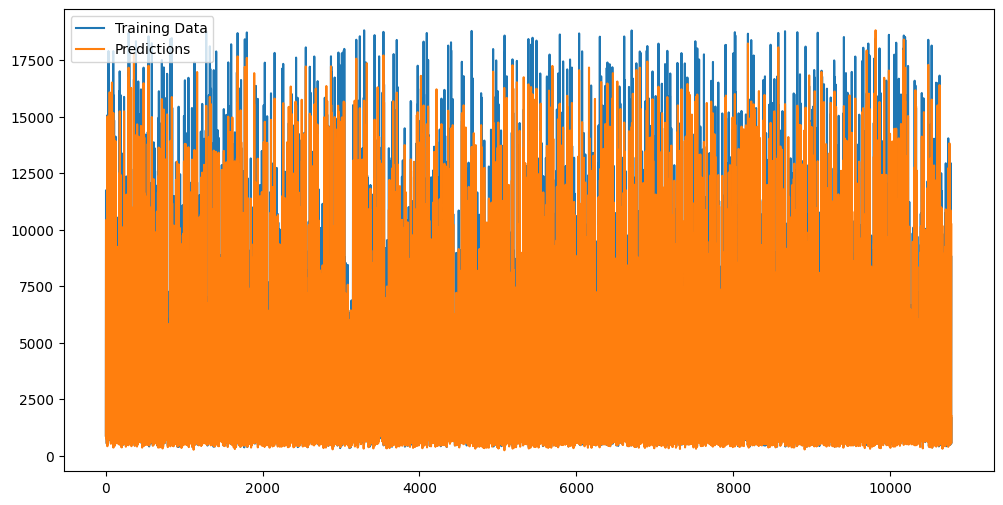

In [ ]:
prediction_results['Actual'].plot(
    legend= True,
    label= 'Training Data',
    figsize=(12,6)
)

prediction_results['Predicted'].plot(
    legend= True,
    label= 'Predictions'
)

#### **Errors Distribution**

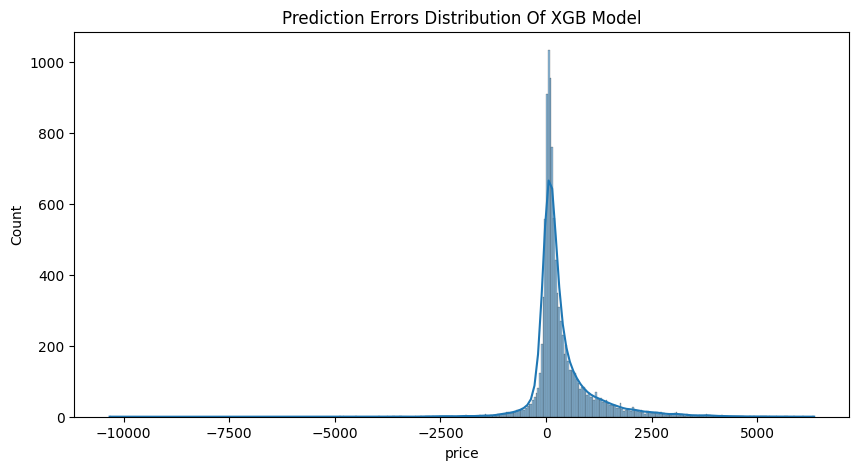

In [ ]:
errors = y_test - y_test_pred

plt.figure(figsize=(10, 5))
sns.histplot(errors, kde=True)
plt.title("Prediction Errors Distribution Of XGB Model")
plt.show()

### **Train the Random Forest model and display its evaluation metrics**

In [ ]:
model_results = []

best_model_name = results_df.iloc[11]['Model']
best_model = Models[best_model_name]

best_technique_name = results_df.iloc[11]['Technique']
best_technique = Scalers[best_technique_name]

if best_technique == 'custom_equilibration':
  X_trans = equilibration_transform(X_train)
  X_test_trans = equilibration_transform(X_test)
elif best_technique == 'custom_arithmetic':
  X_trans = arithmetic_mean_transform(X_train)
  X_test_trans = arithmetic_mean_transform(X_test)
elif best_technique == 'custom_geometric':
  X_trans = geometric_mean_transform(X_train)
  X_test_trans = geometric_mean_transform(X_test)
else:
  X_trans = scaler.fit_transform(X_train)
  X_test_trans = scaler.fit_transform(X_test)


best_model.fit(X_trans, y_train)

y_train_pred = best_model.predict(X_trans)

start_time = process_time()
y_test_pred = best_model.predict(X_test)
end_time = process_time()
cpu_duration_before_scaling = end_time - start_time

start_time = process_time()
y_test_pred = best_model.predict(X_test_trans)
end_time = process_time()
cpu_duration_after_scaling = end_time - start_time


test_mae = mean_absolute_error(y_test, y_test_pred)

test_rmse = root_mean_squared_error(y_test, y_test_pred)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

overfit_gap = train_r2 - test_r2

model_results.append({
      'Model': best_model_name,
      'Technique': best_technique_name,
      'MAE': round(test_mae, 3),
      'RMSE': round(test_rmse, 3),
      'Train R2': round(train_r2, 3),
      'Pred R2': round(test_r2, 3),
      'Overfit Gap': round(overfit_gap, 3),
      'CPU Time Before Scaling (sec)': round(cpu_duration_before_scaling, 3),
      'CPU Time After Scaling (sec)': round(cpu_duration_after_scaling, 3)
  })

model_results_df = pd.DataFrame(model_results)
model_results_df

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning:

X has feature names, but RandomForestRegressor was fitted without feature names



,Model,Technique,MAE,RMSE,Train R2,Pred R2,Overfit Gap,CPU Time Before Scaling (sec),CPU Time After Scaling (sec)
0,Random Forest,Arithmetic mean,266.623,547.885,0.997,0.981,0.016,0.056,0.471


#### **Comparison Between Actual and Predicted Values**

In [ ]:
prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred
})

prediction_results.head(10)

,Actual,Predicted
0,874,1150.701667
1,9273,7850.520000
2,11743,11278.630000
3,1064,1045.820000
4,906,878.350000
5,3528,4201.900000
6,2638,3066.810000
7,894,960.740000
8,2247,2116.260000
9,4548,5325.320000


<Axes: >

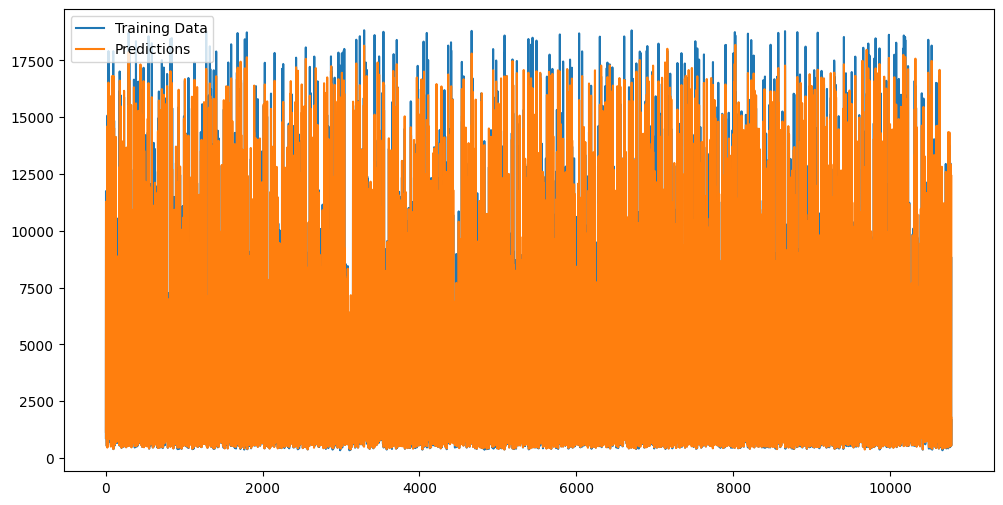

In [ ]:
prediction_results['Actual'].plot(
    legend= True,
    label= 'Training Data',
    figsize=(12,6)
)

prediction_results['Predicted'].plot(
    legend= True,
    label= 'Predictions'
)

#### **Errors Distribution**

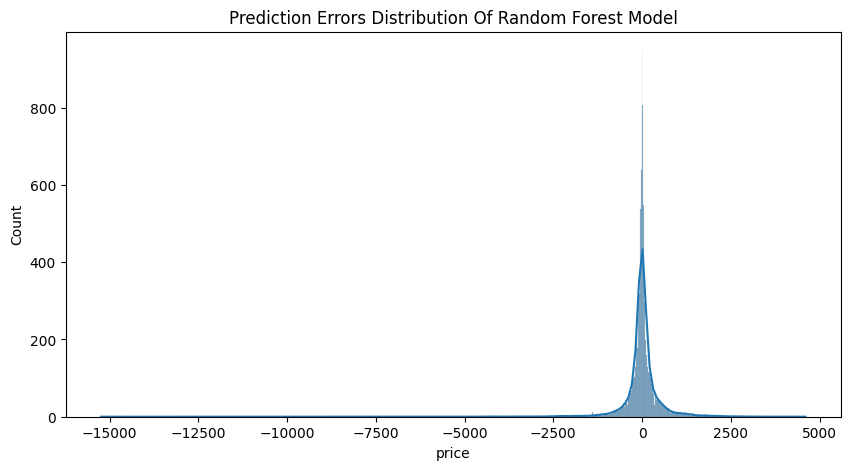

In [ ]:
errors = y_test - y_test_pred

plt.figure(figsize=(10, 5))
sns.histplot(errors, kde=True)
plt.title("Prediction Errors Distribution Of Random Forest Model")
plt.show()

### **Best Model & Scaling Technique**

In [ ]:
model_results_df

,Model,Technique,MAE,RMSE,Train R2,Pred R2,Overfit Gap,CPU Time Before Scaling (sec),CPU Time After Scaling (sec)
0,Random Forest,Arithmetic mean,266.623,547.885,0.997,0.981,0.016,0.056,0.471


### **Save the Files to Disk**

In [ ]:
import joblib
from google.colab import files

joblib.dump(best_model, 'best_diamond_model.pkl')
files.download('best_diamond_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
arr = np.asarray(X_train, dtype=float)
col_means = np.mean(arr, axis=0, keepdims=True)
col_means[col_means == 0] = 1.0

joblib.dump(col_means, 'arithmetic_col_means.pkl')
files.download('arithmetic_col_means.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **8. Insights 📈**

## 📊 Executive Insights Report: Scaling Techniques & Model Performance

## 📌 1. Executive Summary

* **Impact of Scaling on Tree-Based Models:** Feature scaling does not alter predictive performance ($R^2$ and $MAE$), but significantly optimizes computational efficiency by reducing **training and evaluation time (CPU Time)** by up to **49.5%**.
* **Impact of Scaling on Linear Models:** Feature scaling is mandatory and critical. Applying optimal scaling elevated variance explained ($R^2$) by over **20%** and reduced overfitting gap by over **98%**.
* **Final Project Selection:** **Random Forest** paired with **Arithmetic Mean Scaling** was selected as the final production model for predicting diamond prices based on overall accuracy and superior generalization.

---

## 🔍 2. Model Performance Benchmarks (Pre vs. Post-Scaling)

### 🌲 Tree-Based Models

> **Key Finding:** Applying **Arithmetic Mean Scaling** significantly accelerates execution time (CPU Time) without sacrificing model accuracy or error metrics.

| Model | Scaling Technique | Mean $R^2$ | Overfit Gap | Mean MAE | CPU Time (sec) | Improvement / Observations |
| --- | --- | --- | --- | --- | --- | --- |
| **XGBoost** | Pre-Scaling | 0.981 | 0.010 | 280.188 | 0.095 | Baseline |
| **XGBoost** | **Arithmetic Mean** | **0.981** | **0.010** | **280.188** | **0.048** | 🟢 **49.5% reduction** in CPU execution time |
| **Random Forest** | Pre-Scaling | 0.981 | 0.017 | 272.468 | 0.738 | Baseline |
| **Random Forest** | **Arithmetic Mean** | **0.981** | **0.017** | **272.397** | **0.682** | 🟢 Slight decrease in MAE (0.4%) & **7.6% faster** execution |

---

### 📐 Linear Models

> **Key Finding:** Feature scaling drastically mitigates overfitting and leads to substantial gains in predictive power.

| Model | Scaling Technique | Mean $R^2$ | Overfit Gap | Mean MAE | CPU Time (sec) | Improvement / Observations |
| --- | --- | --- | --- | --- | --- | --- |
| **Ridge** | Pre-Scaling | 0.738 | 0.167 | 809.381 | 0.079 | High overfitting gap |
| **Ridge** | **Normalization [-1, 1]** | **0.904** | **0.002** | **808.193** | **0.042** | 🚀 $R^2$ increased by **22.5%**; Overfit gap dropped by **98.0%** |
| **Linear Reg.** | Pre-Scaling | 0.736 | 0.170 | 809.310 | 0.136 | Baseline |
| **Linear Reg.** | **de Buchet & Lp_norm (p=1)** | **0.887** | **0.001** | **879.816** | **0.040** | 🚀 $R^2$ increased by **20.5%**; Overfit gap dropped by **99.4%** |
| **Linear Reg.** | **Arithmetic Mean** | 0.736 | 0.170 | 809.310 | **0.029** | ⚡ **78.7% reduction** in CPU Time (identical accuracy) |

---

## 💡 3. Key Technical Insights

1. **Linear Models Require Uniform Feature Scales:**
* Applying **Normalization [-1, 1]** to **Ridge Regression** successfully closed the overfitting gap from `0.167` down to `0.002`, pushing $R^2$ up to `0.904`.
* **Ridge Regression** benefits the most because regularization penalties directly constrain coefficient magnitudes; when scales are normalized, weight shrinkage functions effectively across all features.


2. **Invariance of Tree Models to Monotonic Scaling:**
* Decision trees rely on ordinal splits rather than absolute vector lengths, meaning $R^2$ and $MAE$ remain unchanged post-scaling.
* The **49.5% CPU Time reduction** in XGBoost is attributed to improved memory layout efficiency and faster floating-point computations on standardized values.


3. **Efficiency of Arithmetic Mean Scaling:**
* Proven to be the most computationally efficient technique when the sole goal is **reducing execution latency** without distorting feature distribution bounds.



---

## 🏆 4. Final Production Model Selection

Following full-dataset retraining and evaluation on the target variable (Diamond Price Prediction):

| Metric | XGBoost (Arithmetic Mean) | Random Forest (Arithmetic Mean) | Winner |
| --- | --- | --- | --- |
| **MAE** *(Lower is better)* | 478.221 | **266.623** | 🏆 **Random Forest** |
| **RMSE** *(Lower is better)* | 847.859 | **547.885** | 🏆 **Random Forest** |
| **Pred $R^2$** *(Higher is better)* | 0.955 | **0.981** | 🏆 **Random Forest** |
| **Overfit Gap** *(Lower is better)* | 0.036 | **0.016** | 🏆 **Random Forest** |
| **CPU Time After Scaling** | **0.045 sec** | 0.471 sec | XGBoost |

### 📌 Decision Rationalization:

While **XGBoost** demonstrates faster training speed, **Random Forest** delivers superior accuracy and robustness across all core metrics:

* **~44% lower Mean Absolute Error (MAE)** ($266.62$ vs $478.22$).
* **~35% lower Root Mean Squared Error (RMSE)**, proving stronger resilience against large price prediction variances.
* **Tighter generalization gap** ($0.016$).

**Decision:** **Random Forest + Arithmetic Mean Scaling** is designated as the primary model for deployment.

# **The End 🤝**